# Optimization

This section describes how to obtain [gradients](#Gradients) for more efficient optimization and how to speedup execution via [parallelization](#Parallelization).

Finally, a few [optimization examples](#Optimization-with-Topfarm2) is demonstrated using Topfarm2

## Gradients

PyWake supports three methods for computing gradients:


| Method               | Pro                                  | Con |
| :------               | :---                                  | :--- |
| Finite difference (`fd`)   | - Works out of the box in most cases<br>- Fast for small problems | - Less accurate <br>- Sensitive to stepsize<br>- Requires `n+1` function evaluation |
| Complex step (`cs`)        | - More accurate<br>- Works out of the box or with a few minor changes<br> - Fast for small problems | - Requires `n` function evaluations
| Automatic differentiation (`autograd`)           | - Exact result<br>- Requires 1 smart function evaluation | - `numpy` must be replaced with `autograd.numpy`<br>- Often code changes and debugging is required<br>- Debugging is very hard<br>- Gradient functions (e.g. using `fd` or `cs`) must be specified if `autograd` fails

### Example problem

To demonstrate the three methods we first define an example function, `f(x)`, with one input vector of three elements, `x = [1,2,3]`

$ f(x)=\sum_x{2x^3\sin(x)}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def f(x):
    return np.sum((2 * x**3) * np.sin(x))

def df(x):
    # analytical gradient used for comparison
    return 6*x**2 * np.sin(x)  + 2*x**3 * np.cos(x)

x = np.array([1,2,3], dtype=float)

Plot variation+gradients of `f` with respect to $x_0, x_1, x_2$

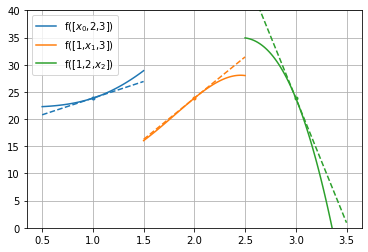

In [2]:
dx_lst = np.linspace(-.5,.5,100)
import matplotlib.pyplot as plt
from py_wake.utils.plotting import setup_plot
for i in range(3):
    label="f([1,2,3])".replace(str(i+1),f"$x_{i}$")
    c = plt.plot(x[i] + dx_lst, [f(x + np.roll([dx,0,0],i)) for dx in dx_lst], label=label)[0].get_color()
    plt.plot(x[i]+[-.5,.5], f(x) + df(x)[i]*np.array([-.5,.5]), '--', color=c)
    plt.plot(x[i], f(x), '.', color=c)
setup_plot(ylim=[0,40])
plt.legend()


### Finite difference `fd`

$\frac{d f(x)}{dx} = \frac{f(x+h) - f(x)}{h}$

Finite difference applied to the example function:


In [3]:
print ("Analytical gradient:", list(df(x)))
h = 1e-6
for i in range(3):
    print (f"Finite difference gradient wrt. x{i}:", (f(x+np.roll([h,0,0],i)) - f(x))/h)

Analytical gradient: [6.129430520583658, 15.164788859062082, -45.83911438119122]
Finite difference gradient wrt. x0: 6.129437970514573
Finite difference gradient wrt. x1: 15.164782510623809
Finite difference gradient wrt. x2: -45.839169114714196


In  this example the gradients are accurate to 4th or 5th decimal. The accuracy, however, is highly dependent on the step size, `h`. If the step size is too small the result becomes inaccurate due to nummerical issues. If the step size, on the other hands, becomes to big, then the result represents the gradient of a neighboring point. 
This compromize is illusated below:

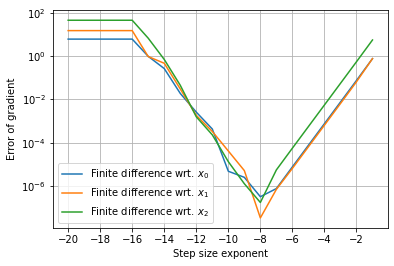

In [4]:
h_lst = 10.**(-np.arange(1,21)) # step sizes [1e-1, ..., 1e-20]

for i in range(3):
    # Plot error compared to analytical gradient, df(x)
    plt.semilogy(np.log10(h_lst), [np.abs(df(x)[i] - (f(x+np.roll([h,0,0],i))-f(x))/h) for h in h_lst], 
                 label=f'Finite difference wrt. $x_{i}$')
plt.xticks(np.arange(-20,-1,2))
setup_plot(ylabel='Error of gradient', xlabel='Step size exponent')

### Complex step

The complex step is described [here](https://blogs.mathworks.com/cleve/2013/10/14/complex-step-differentiation/).

It utilizes that 

$\frac {d f(x)}{x}= \frac{\operatorname{Im}(f(x+ih))}{h}+O(h^2)$

Applied to the example function, the result is accurate to the 15th decimal.

In [5]:
print ("Analytical gradient:", list(df(x)))
h = 1e-10

for i in range(3):
    print (f"Finite difference gradient wrt. x{i}:", np.imag(f(x+np.roll([h*1j,0,0],i)))/h)

Analytical gradient: [6.129430520583658, 15.164788859062082, -45.83911438119122]
Finite difference gradient wrt. x0: 6.129430520583658
Finite difference gradient wrt. x1: 15.164788859062082
Finite difference gradient wrt. x2: -45.83911438119122


Furthermore, the result is much less sensitive to the step size as seen below

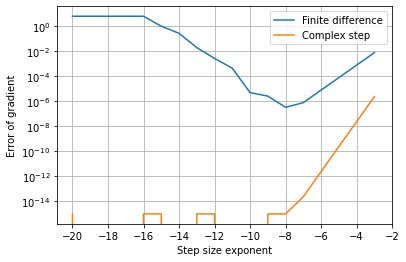

In [6]:
h_lst = 10.**(-np.arange(3,21))

plt.semilogy(np.log10(h_lst), [np.abs(df(x)[0] - (f(x+[h,0,0])-f(x))/h) for h in h_lst], label='Finite difference')
plt.semilogy(np.log10(h_lst), [np.abs(df(x)[0] - np.imag(f(x+[h*1j,0,0]))/h) for h in h_lst], label='Complex step')
plt.xticks(np.arange(-20,-1,2))
setup_plot(ylabel='Error of gradient', xlabel='Step size exponent')

#### Common code changes

The complex step method calls the function with a complex number, i.e. all intermediate functions and routines must support  complex number. A few `numpy` functions has different or undefined behaviour for complex numbers, so often a few changes is required. In PyWake the module, `py_wake.utils.gradients`, contains a set of replacement functions that supports complext number, e.g.:

- `abs`
  - For a real value, `x`, `abs(x)` returns the positive value, while for a complex number, it returns the distance from 0 to z, $abs(a+bi)= \sqrt{a^2+b^2}$. 
  - In most cases `abs` should therefore be replaced by `gradients.cabs`, which returns `np.where(x<0,-x,x)`)
- `np.hypot(a,b)`
  - `np.hypot` does not support complex numbers
  - replace with `gradients.hypot`, which returns `np.sqrt(a\*\*2+b\*\*2)` if `a` or `b` is complex
- `np.interp(xp,x,y)`
  - replace with `gradients.interp(xp,x,y)`
- `np.logaddexp(x,y)`
  - replace with  `gradients.logaddexp(x,y)` 
  
Furthermore, the imaginary part must be preserved when creating new arrays, i.e.
- `np.array(x,dtype=float)` -> `np.array(x,dtype=(float, np.complex128)[np.iscomplexobj(x)])`


### Autograd

[Autograd](https://github.com/HIPS/autograd) is a python package that can automatically differentiate native Python and Numpy code.

Autograd performs a two step automatic differentiation process.

First the normal result is calculated and during this process autograd setups up a calculation tree where each element in the tree holds the associated gradient functions:

<img src="../_static/autograd_calculation.svg" width="400"/>


For most numpy functions, the associated gradient function is predefined when using `autograd.numpy` instead of `numpy`. You can see the autograd module that defines the gradients of numpy functions [here](https://github.com/HIPS/autograd/blob/master/autograd/numpy/numpy_vjps.py#L32) and the functions used in the example is shown here:

```python
defvjp(anp.multiply,    lambda ans, x, y : unbroadcast_f(x, lambda g: y * g),
                        lambda ans, x, y : unbroadcast_f(y, lambda g: x * g))
defvjp(anp.add,         lambda ans, x, y : unbroadcast_f(x, lambda g: g),
                        lambda ans, x, y : unbroadcast_f(y, lambda g: g))
defvjp(anp.power,
    lambda ans, x, y : unbroadcast_f(x, lambda g: g * y * x ** anp.where(y, y - 1, 1.)),
    lambda ans, x, y : unbroadcast_f(y, lambda g: g * anp.log(replace_zero(x, 1.)) * x ** y))
defvjp(anp.sin,    lambda ans, x : lambda g: g * anp.cos(x))
```

In the second step, the gradients are calculated by backward propagation
<img src="../_static/autograd_differentiation.svg" width="400"/>

Applied to the example function, `autograd`, gives the exact results.

In [7]:
from autograd import elementwise_grad
from autograd import numpy as anp
def f_anp(x):
    return anp.sum((2 * x**3) * anp.sin(x))

print ("Analytical gradient:", list(df(x)))
print (f"Autograd gradient:", list(elementwise_grad(f_anp)(x)))

Analytical gradient: [6.129430520583658, 15.164788859062082, -45.83911438119122]
Autograd gradient: [6.129430520583658, 15.164788859062082, -45.83911438119122]


Note, a new function, `f_anp` implemented with `autograd.numpy` instead of `numpy` is needed for autograd to work out of the box.

In PyWake, however, a wrapper, `py_wake.utils.gradients.autograd` has been implemented that handles the numpy replacemenet and several other issues, automatically:

In [8]:
from py_wake.utils.gradients import autograd
autograd(f)(x)

array([  6.12943052,  15.16478886, -45.83911438])

#### Common code changes

- `x[m] = 0` -> `x = np.where(m,0,x)`
  - Item assignment not supported
  

### Scalability of example problem
As seen in the examples, autograd computed the gradients with respect to all input elements in one smart (but slow) function evaluation, while finite difference and complex step required `n + 1` and `n` function evaluations, respectively.

This difference has a high impact on the performance of large scale problems. The plot below shows the time required to compute the gradients as a function of the number of elements in the input vector. In this example the `fd`, `cs` and `autograd` functions from `py_wake.utils.gradients` is utilized.

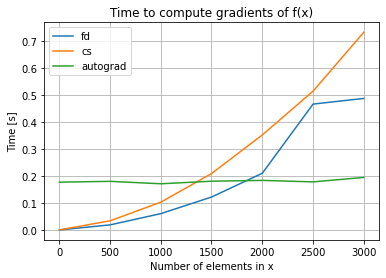

In [9]:
from py_wake.utils.gradients import fd, cs, autograd
from py_wake.tests.check_speed import timeit

n_lst = np.arange(1,3500,500)
x_lst = [np.random.random(n) for n in n_lst]
def get_gradients(method,x):
    return method(f, vector_interdependence=True)(x)

for method in  [fd, cs, autograd]:
    plt.plot(n_lst, [np.mean(timeit(get_gradients, min_time=.2)(method,x)[1]) for x in x_lst], label=method.__name__)
setup_plot(title='Time to compute gradients of f(x)', xlabel='Number of elements in x', ylabel='Time [s]')

### Gradients in PyWake

As described above, PyWake, contains a module, `py_wake.utils.gradients` which defines the three methods, `fd`, `cs` and `autograd`, as well as a number of helper functions and constructs.

With only a few exceptions, all PyWake models, turbines and sites support the three gradient methods.

Unfortunately, autograd is not working very well with xarray, i.e. the normal xarray `SimulationResult` must be bypassed. This mean that you can compute gradients of the [AEP](#Gradients-of-AEP) or [WS, TI, Power and custom functions](#Gradients-of-WS,-TI,-Power-and-custom-functions) via the results returned by the `WindFarmModel.calc_wt_interaction` method.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from py_wake.examples.data.hornsrev1 import Hornsrev1Site, HornsrevV80
from py_wake.utils.gradients import fd, cs, autograd
from py_wake.utils.profiling import timeit
from py_wake.utils.plotting import setup_plot
from py_wake.deficit_models.gaussian import ZongGaussian, BastankhahGaussian
from py_wake.deflection_models.jimenez import JimenezWakeDeflection
from py_wake.turbulence_models.crespo import CrespoHernandez

In [11]:
site = Hornsrev1Site()
wt = HornsrevV80()
wfm = ZongGaussian(site, wt, deflectionModel=JimenezWakeDeflection(), turbulenceModel=CrespoHernandez())

def get_xy(N, cols=10):
    # return x,y positions for a <cols> column wind farm with N wind turbines 
    return [np.ravel(v)*5*wt.diameter() for v in np.meshgrid(np.arange(cols), np.arange(N//cols))]

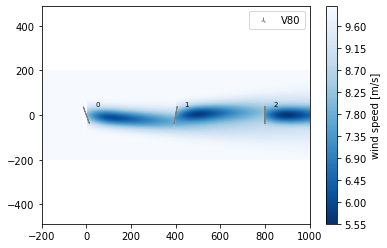

In [12]:
x,y = get_xy(3,3)
wfm(x,y,wd=[270],ws=10, yaw=[20,-10,0]).flow_map().plot_wake_map()

#### Gradients of AEP
The gradients of the AEP can be computed by the `aep_gradients` method of `WindFarmModel` with respect to most of the input arguments. 

In [13]:
for wrt_arg in ['x','y','xy','h', 'yaw']:
    daep = wfm.aep_gradients(gradient_method=autograd, wrt_arg=wrt_arg)(x=x,y=y, h=[69,70,71], yaw=[20,-10,1])
    print (f"Gradients of AEP wrt. {wrt_arg}", daep)

Gradients of AEP wrt. x [-1.14696413e-03 -7.80093407e-05  1.22497347e-03]
Gradients of AEP wrt. y [ 0.00035313 -0.00070408  0.00035094]
Gradients of AEP wrt. xy [[-1.14696413e-03 -7.80093407e-05  1.22497347e-03]
 [ 3.53134679e-04 -7.04076510e-04  3.50941831e-04]]
Gradients of AEP wrt. h [-2.11882021e-04 -4.71201387e-06  2.16594034e-04]
Gradients of AEP wrt. yaw [-0.07908633  0.03984189 -0.00430088]


##### AEP gradients with respect to (x,y) or (xy)

When computing gradients with autograd, a significant speed up (40-50%) can be obtained by computing the gradients with respect to both `x` and `y` in one go,

```
wfm.aep_gradients(gradient_method=autograd, wrt_arg='xy')(x,y)
```

instead of first computing with respect to `x` and then with respect to `y`,

```
wfm.aep_gradients(gradient_method=autograd, wrt_arg='x')(x,y)
wfm.aep_gradients(gradient_method=autograd, wrt_arg='y')(x,y)
```

For finite difference and complex step, the speed is similar.

In [14]:
wfm = BastankhahGaussian(site, wt)

def get_aep(wrt_arg_lst, method):
    return lambda x,y : [wfm.aep_gradients(gradient_method=method, wrt_arg=wrt_arg)(x,y) for wrt_arg in wrt_arg_lst]
    
N_lst = np.arange(10,50,10) # number of wt
t_x_y_autograd = [timeit(get_aep(['x','y'], method=autograd))(*get_xy(N))[1] for N in N_lst]
t_xy_autograd = [timeit(get_aep(['xy'], method=autograd))(*get_xy(N))[1] for N in N_lst]
t_x_y_fd = [timeit(get_aep(['x','y'], method=fd))(*get_xy(N))[1] for N in N_lst[:2]]
t_xy_fd = [timeit(get_aep(['xy'], method=fd))(*get_xy(N))[1] for N in N_lst[:2]]

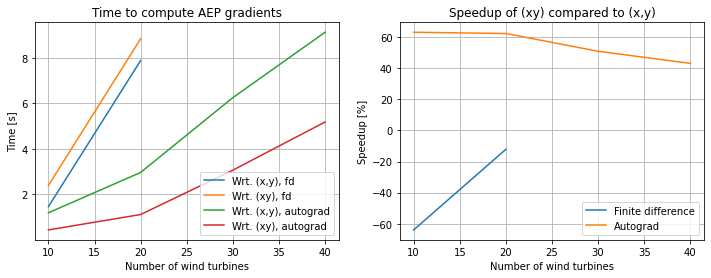

In [15]:
ax1,ax2 = plt.subplots(1,2, figsize=(12,4))[1]
ax1.plot(N_lst[:2], t_x_y_fd, label='Wrt. (x,y), fd')
ax1.plot(N_lst[:2], t_xy_fd, label='Wrt. (xy), fd')
ax1.plot(N_lst, t_x_y_autograd, label='Wrt. (x,y), autograd')
ax1.plot(N_lst, t_xy_autograd, label='Wrt. (xy), autograd')
setup_plot(ax=ax1, title='Time to compute AEP gradients', ylabel='Time [s]', xlabel='Number of wind turbines')

ax2.plot(N_lst[:2], (np.array(t_x_y_fd) - t_xy_fd)/t_x_y_fd*100, label='Finite difference')
ax2.plot(N_lst, (np.array(t_x_y_autograd) - t_xy_autograd)/t_x_y_autograd*100, label='Autograd')
setup_plot(ax=ax2, title="Speedup of (xy) compared to (x,y)", ylabel='Speedup [%]', xlabel='Number of wind turbines')

#### Gradients of WS, TI, Power and custom functions

The normal `WindFarmModel.__call__` method, which is invoked by `wfm(x,y,...)` calls `WindFarmModel.calc_wt_interaction` and packs the result into a xarray dataset. This step breaks the autograd data flow. We therefore need to call [`WindFarmModel.calc_wt_interaction`](https://topfarm.pages.windenergy.dtu.dk/PyWake/api/WindFarmModel.html#py_wake.wind_farm_models.wind_farm_model.WindFarmModel.calc_wt_interaction) directly. The indexes of the relevant output of `WindFarmModel.calc_wt_interaction` is

0. WS_eff_ilk
1. TI_eff_ilk
2. power_ilk
3. ct_ilk

Below are a few basic examples

##### Mean power wrt (x,y) - 2 x 1D inputs, one output
Compute the gradients of the mean power with respect to both x and y

In [16]:
def mean_power(x,y):
    power_ilk = wfm.calc_wt_interaction(x_i=x, y_i=y)[2] # index 2 = power_ilk
    return power_ilk.mean()
mean_power_gradients_function = autograd(mean_power,vector_interdependence=True, argnum=[0,1])
d_aep = mean_power_gradients_function(x, y)
print (d_aep)
print (np.shape(d_aep))

[array([-2.53542447e+01, -1.77635684e-15,  2.53542447e+01]), array([ 2.33973538e-13,  5.38529120e-15, -2.39358830e-13])]
(2, 3)


##### Mean power wrt (xy) - 1D input (2 x 1D merged into 1D), one output
Compute the gradients of the mean power with respect to both merged xy, see also [AEP gradients with respect to (x,y) or (xy)](#AEP-gradients-with-respect-to-(x,y)-or-(xy))

In [17]:
def mean_power(xy):
    x,y = np.reshape(xy,(2,-1)) # unpack merged xy
    power_ilk = wfm.calc_wt_interaction(x_i=x, y_i=y)[2] # index 2 = power_ilk
    return power_ilk.mean()
mean_power_gradients_function = autograd(mean_power,vector_interdependence=True)
d_aep = mean_power_gradients_function(np.r_[x, y]).reshape(2,-1) # reshape gradients from (xy) to (x,y)
print (d_aep)
print (d_aep.shape)

[[-2.53542447e+01 -1.77635684e-15  2.53542447e+01]
 [ 2.33973538e-13  5.38529120e-15 -2.39358830e-13]]
(2, 3)


##### Power pr wind speed wrt. x - 1D input, 1D output

Compute the gradients of the power pr wind speed (i.e. power meaned over wind turbine and direction) with respect to x.

In [18]:
def ws_power(x):
    power_ilk = wfm.calc_wt_interaction(x_i=x, y_i=y)[2] # index 2 = power_ilk
    return power_ilk.mean((0,1)) # mean power pr wind speed
ws_power_gradients_function = autograd(ws_power,vector_interdependence=True)
np.shape(ws_power_gradients_function(x))

(23, 3)

#### Manual gradient functions for autograd

Autograd can be supplemented with custom gradient functions, that bypass the automatic differentiation process and returns the gradients directly.
This is usefull for functions that cannot be analytically differentiated by autograd, e.g. interpolation functions. Some commonly used functions have been implemented in `py_wake.utils.gradients`, e.g.

- trapz (np.trapz)
- interp (np.interp)
- PchipInterpolator (scipy.PchipInterpolator)
- UnivariateSpline (scipy.UnivariateSpline)


Specifying the gradient functions and ensuring that they return the gradients in the right dimensions is, however, not trivial. 

It was expected that that the computational time could be reduced by specifying maually-implemented gradient functions of some time-critical functions. An example is shown below, where functions to calculate the gradients of `calc_deficit` of the `BastankhahGaussianDeficit` with respect to all inputs are implemented.

In [19]:
from py_wake.deficit_models.gaussian import BastankhahGaussianDeficit
from py_wake.utils.gradients import set_vjp
import warnings
class BastankhahGaussianDeficitGradients(BastankhahGaussianDeficit):
    def __init__(self, k=0.0324555, ceps=.2, use_effective_ws=False):
        BastankhahGaussianDeficit.__init__(self, k=k, ceps=ceps, use_effective_ws=use_effective_ws)
        self.calc_deficit = set_vjp([self.get_ddeficit_dx(i) for i in range(6)])(self.calc_deficit)
                                                                                 
    def get_ddeficit_dx(self, argnum):
        import numpy as np  # override autograd.numpy
        from numpy import newaxis as na

        def ddeficit_dx(ans, WS_ilk, WS_eff_ilk, D_src_il, dw_ijlk, cw_ijlk, ct_ilk, **kwargs):
            _, _, _, K = np.max([dw_ijlk.shape, cw_ijlk.shape, WS_ilk[:, na].shape], 0)
            eps = 0
            WS_ref_ilk = (WS_ilk, WS_eff_ilk)[self.use_effective_ws]
            ky_ilk = self.k_ilk(**kwargs)
            beta_ilk = 0.5*(1 + 1/np.sqrt(1-ct_ilk))
            sigma_ijlk = ky_ilk[:, na]*dw_ijlk * (dw_ijlk > eps) + \
                .2*D_src_il[:, na, :, na]*np.sqrt(beta_ilk[:, na])
            a_ijlk = ct_ilk[:, na] / (8. * (sigma_ijlk / D_src_il[:, na, :, na])**2)
            sqrt_ijlk = np.sqrt(np.maximum(0., 1 - a_ijlk))
            layout_factor_ijlk = WS_ref_ilk[:, na] * (dw_ijlk > eps) * np.exp(-0.5 * (cw_ijlk / sigma_ijlk)**2)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                if argnum == 0:
                    dWS = ans / WS_ref_ilk[:, na]
                elif argnum == 1:
                    dWS_eff = ans / WS_eff_ilk[:, na]
                elif argnum == 2:
                    dD_sqrt_pos = (a_ijlk*(1/D_src_il[:, na, :, na]-0.2*np.sqrt(beta_ilk[:, na])/sigma_ijlk)/sqrt_ijlk + \
                            (1-sqrt_ijlk)*(cw_ijlk**2/sigma_ijlk**3)*.2*np.sqrt(beta_ilk[:, na])) * layout_factor_ijlk
                    dD_sqrt_neg =(cw_ijlk**2/sigma_ijlk**3)*.2*np.sqrt(beta_ilk[:, na]) * layout_factor_ijlk
                    dD = np.where(sqrt_ijlk == 0, dD_sqrt_neg, dD_sqrt_pos)
                elif argnum == 3:
                    ddw_sqrt_pos = (-a_ijlk / sqrt_ijlk + (1 - sqrt_ijlk) * (cw_ijlk / sigma_ijlk)**2) * \
                            ky_ilk[:, na] / sigma_ijlk * layout_factor_ijlk
                    ddw_sqrt_neg = (cw_ijlk / sigma_ijlk)**2 * ky_ilk[:, na] / sigma_ijlk * layout_factor_ijlk
                    ddw = np.where(sqrt_ijlk == 0, ddw_sqrt_neg, ddw_sqrt_pos)
                elif argnum == 4:
                    dcw = ans * (- cw_ijlk / (sigma_ijlk**2))
                elif argnum == 5:
                    dsigmadct_ilk = 0.2*D_src_il[:, :, na]/(8*np.sqrt(beta_ilk*(1-ct_ilk)**3))
                    dct_sqrt_pos = (a_ijlk*(1/(2*ct_ilk[:, na])-dsigmadct_ilk[:, na]/sigma_ijlk)/sqrt_ijlk + \
                            (1-sqrt_ijlk)*(cw_ijlk**2/sigma_ijlk**3)*dsigmadct_ilk[:, na])*layout_factor_ijlk
                    dct_sqrt_neg = (cw_ijlk**2/sigma_ijlk**3)*dsigmadct_ilk[:, na]*layout_factor_ijlk
                    dct = np.where(sqrt_ijlk == 0, dct_sqrt_neg, dct_sqrt_pos)

            def dWS_ilk(g):
                r = g * dWS[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                j = np.r_[np.where(g)[1], 0][0]
                ilk = (slice(None), j)
                return r[ilk]

            def dWS_eff_ilk(g):
                r = g * dWS_eff[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                j = np.r_[np.where(g)[1], 0][0]
                ilk = (slice(None), j)
                return r[ilk]

            def dD_src_il(g):
                r = g * dD[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                j = np.r_[np.where(g)[1], 0][0]
                k = np.r_[np.where(g)[3], 0][0]
                il = (slice(None), j, slice(None), k)
                return r[il]

            def ddw_ijlk(g):
                r = g * ddw[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                if dw_ijlk.shape[-1] == 1 and K > 1:
                    # If dw_ijlk is independent of ws, i.e. last dimension is 1 while len(ws)>1
                    # then we need to sum the gradients wrt. wind speeds
                    r = r.sum(3)[:, :, :, na]
                return r[:, :, :, 0:dw_ijlk.shape[3]]

            def dcw_ijlk(g):
                r = g * dcw[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                if cw_ijlk.shape[-1] == 1 and K > 1:
                    # If cw_ijlk is independent of ws, i.e. last dimension is 1 while len(ws)>1
                    # then we need to sum the gradients wrt. wind speeds
                    r = r.sum(3)[:, :, :, na]
                return r[:, :, :, 0:cw_ijlk.shape[3]]

            def dct_ilk(g):
                r = g * dct[:g.shape[0], :g.shape[1], :g.shape[2], :g.shape[3]]
                j = np.r_[np.where(g)[1], 0][0]
                ilk = (slice(None), j)
                return r[ilk]

            return [dWS_ilk, dWS_eff_ilk, dD_src_il, ddw_ijlk, dcw_ijlk, dct_ilk][argnum]
        return ddeficit_dx

In this example, however, the model with manual gradient functions performs worse than the original where autograd derives the gradient functions automatically.

In [20]:
from py_wake.wind_farm_models import PropagateDownwind
from py_wake.examples.data.hornsrev1 import wt16_x, wt16_y
wfm_autograd = PropagateDownwind(site, wt, BastankhahGaussianDeficit())
wfm_manual = PropagateDownwind(site, wt, BastankhahGaussianDeficitGradients())

ws = np.arange(4,26)
x,y = wt16_x, wt16_y
ref, t_auto = timeit(lambda: wfm_autograd.aep_gradients(gradient_method=autograd, wrt_arg='xy')(x, y, ws=ws))()
res, t_manual = timeit(lambda: wfm_manual.aep_gradients(gradient_method=autograd, wrt_arg='xy')(x, y, ws=ws))()
np.testing.assert_array_almost_equal(res, ref, 4)
print ("Time, automatic gradients", np.mean(t_auto))
print ("Time, manual gradients", np.mean(t_manual))

Time, automatic gradients 1.0149989128112793
Time, manual gradients 0.937999963760376


### Scalability of AEP gradients

As seen in the section [Scalability of example problem](#Scalability-of-example-problem), the autograd scales much better with the number of input variables than finite difference and complex step. 

When considering large wind farms, autograd is convincing outperforming both finite difference and complex step, but it also requires much more memory.

The following plots are based on simulation performance on the Sophia HPC cluster.

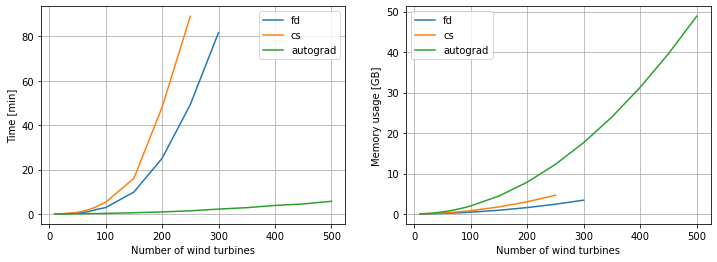

In [21]:
data = {
    "fd":((10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150,200, 250, 300),
          [0.89, 3.06, 7.13, 14.77, 24.46, 41.06, 64.46, 105.98, 140.76, 171.53, 590.46, 1501.62, 2957.65, 4904.31],
          [14.1, 31.9, 58.8, 92.2, 135.3, 184.2, 240.6, 303.1, 373.6, 450.7, 946.5, 1620.8, 2470.1, 3500.5]),   
"cs":((10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 250),
      [1.18, 4.9, 12.44, 25.58, 44.56, 72.82, 115.46, 171.42, 245.15, 312.9, 960.64, 2883.04, 5345.27],
      [22.3, 55.7, 107.6, 171.0, 244.1, 338.7, 442.7, 566.9, 690.9, 839.0, 1787.4, 3088.9, 4742.4]),
"autograd":((10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 250, 300, 350, 400, 450, 500),
            [0.32, 0.78, 1.52, 2.49, 3.75, 5.33, 7.14, 9.12, 11.43, 14.02, 32.35, 53.73, 84.94, 130.53, 169.34, 229.62, 270.19, 342.01],
            [26.7, 92.9, 196.4, 340.0, 525.9, 749.6, 1011.1, 1312.2, 1656.0, 2039.7, 4555.0, 8066.8, 12569.9, 18072.6, 24568.2, 32069.6, 40558.9, 50036.6]),
       }
ax1,ax2 = plt.subplots(1,2, figsize=(12,4))[1]
for k,(n,t,m) in data.items():
    ax1.plot(n,np.array(t)/60, label=k)
    ax2.plot(n,np.array(m)/1024, label=k)
setup_plot(ax1, xlabel='Number of wind turbines', ylabel='Time [min]')
setup_plot(ax2, xlabel='Number of wind turbines', ylabel='Memory usage [GB]')

## Chunkify and Parallelization

PyWake makes it easy to chunkify the run wind farm simulations see also section [Run Wind Farm Simulation](https://topfarm.pages.windenergy.dtu.dk/PyWake/notebooks/RunWindFarmSimulation.html)

This construct is also available and usefull when computing gradients to reduce the memory usage and/or speedup the computation by parallel execution

The arguments, `wd_chunks`, `ws_chunks` and `n_cpu` is available in the `aep`, `calc_wt_interaction` and `aep_gradients` methods.



In [22]:
import numpy as np
import matplotlib.pyplot as plt
from py_wake.deficit_models.noj import NOJ
from py_wake.examples.data.hornsrev1 import Hornsrev1Site, HornsrevV80, wt_x, wt_y, wt16_x, wt16_y
from py_wake.utils.profiling import timeit
import multiprocessing
from py_wake.utils.gradients import autograd, fd

In [23]:
site = Hornsrev1Site()
wt = HornsrevV80()
wfm = NOJ(site, wt)
x,y = wt16_x,wt16_y

### AEP

In [24]:
wfm.aep(x, y, n_cpu=None)

143.15156836570173

### WS, TI, Power and custom functions

In [25]:
def mean_power(x,y):
    power_ilk = wfm.calc_wt_interaction(x_i=x, y_i=y, n_cpu=None)[2] # index 2 = power_ilk
    return power_ilk.mean()

mean_power(x,y)

1434559.2530234456

### AEP gradients

In [Gradients of AEP](#Gradients-of-AEP), the `aep_gradients` method was used like this:

In [26]:
gradient_function = wfm.aep_gradients(fd, wrt_arg='xy')
daep = gradient_function(x=x,y=y)

When dealing with chunkification and parallelization, the `aep_gradients` must be used in a slightly different way:

In [27]:
daep = wfm.aep_gradients(fd, wrt_arg='xy', n_cpu=None, x=x, y=y)

Note, in this case, the arguments normally passed to `wfm.aep` (here `x` and `y`) are passed directly to the `wfm.aep_gradients` method as keyword arguments and the method returns the gradients results instead of a function.

### Gradients of WS, TI, Power and custom functions

Is not implemented yet

## Optimization with Topfarm2

In the following sections the examples are optimized using [Topfarm2](https://topfarm.pages.windenergy.dtu.dk/TopFarm2/), an open source Python package developed by DTU Wind Energy to help with wind-farm optimizations. It has a lot of nice built-in features and wrappers

In [28]:
# install topfarm if not present
try:
    import topfarm
except ImportError:
    !pip install topfarm --user

C:\Anaconda3_2019_10\envs\py39\lib\site-packages\openmdao\utils\general_utils.py:128: OMDeprecationWarning:simple_warning is deprecated. Use openmdao.utils.om_warnings.issue_warning instead.
C:\Anaconda3_2019_10\envs\py39\lib\site-packages\openmdao\utils\notebook_utils.py:157: UserWarning:Tabulate is not installed. Run `pip install openmdao[notebooks]` to install required dependencies. Using ASCII for outputs.


### Example, optimize AEP wrt. wind turbine position, x,y

In this example we optimize the AEP of the IEAWind Task 37 Case Study 1.

As TopFarm2 already contains a cost model component, `PyWakeAEPCostModelComponent`, for this kind of problem, setting up the problem is really simple.

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from py_wake.deficit_models.gaussian import IEA37SimpleBastankhahGaussian
from py_wake.examples.data.iea37._iea37 import IEA37Site, IEA37WindTurbines
from py_wake.utils.gradients import autograd, fd, cs
from topfarm._topfarm import TopFarmProblem
from topfarm.cost_models.py_wake_wrapper import PyWakeAEPCostModelComponent
from topfarm.constraint_components.boundary import CircleBoundaryConstraint
from topfarm.constraint_components.spacing import SpacingConstraint
from topfarm.easy_drivers import EasyScipyOptimizeDriver

def get_topfarmProblem_xy(n_wt, grad_method, maxiter):
    site = IEA37Site(n_wt)
    wt = IEA37WindTurbines()
    wfm = IEA37SimpleBastankhahGaussian(site, wt)
    x, y = site.initial_position.T
    return TopFarmProblem(design_vars={'x': x, 'y': y},
                          cost_comp=PyWakeAEPCostModelComponent(windFarmModel=wfm, n_wt=len(x), grad_method=grad_method,
                                                                wd=np.arange(0, 360, 22.5), ws=[9.8]),
                          driver=EasyScipyOptimizeDriver(maxiter=maxiter),
                          constraints=[CircleBoundaryConstraint(center=[0, 0], radius=np.round(np.hypot(x, y).max())),
                                       SpacingConstraint(min_spacing=2 * wt.diameter())])

In [30]:
def optimize_and_plot(n_wt, maxiter, methods=[autograd, fd,cs]):
    plt.title(f'{n_wt} Wind turbines')
    for method in methods:
        tf = get_topfarmProblem_xy(n_wt,method,maxiter)
        cost, state, recorder = tf.optimize()
        t,aep = [recorder[v] for v in ['timestamp','AEP']]
        plt.plot(t-t[0],aep, label=getattr(method,'__name__', "None"))
    plt.legend()
    plt.ylabel('AEP [GWh]')
    plt.xlabel('Time [s]')    

Optimize the site with 16 wind turbines. Below the number of iterations is limited to 3

INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
Iteration limit reached    (Exit mode 9)
            Current function value: -366.9977425847346
            Iterations: 3
            Function evaluations: 3
            Gradient evaluations: 3
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
INFO: check

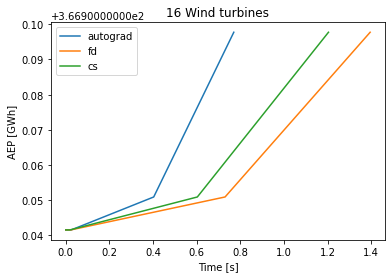

In [31]:
optimize_and_plot(n_wt=16, maxiter=3)

Optimize the site with 64 wind turbines. Below the number of iterations is limited to 3

INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
Iteration limit reached    (Exit mode 9)
            Current function value: -1295.3898337205421
            Iterations: 3
            Function evaluations: 3
            Gradient evaluations: 3
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
INFO: chec

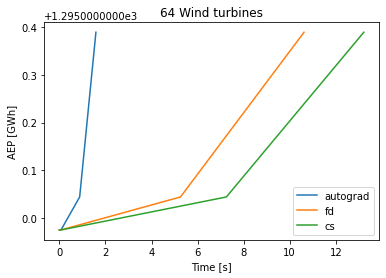

In [32]:
optimize_and_plot(n_wt=64, maxiter=3)

### Optimize x wrt. y

To optimize x wrt. y, you simply need to setup a function, `x = f(y)`.

In the examle below, we will use a wind turbine that can be de-rated

#### De-ratable wind turbine

The relation between power and ct of the de-ratable wind turbine is obtained from 1D momentum theory

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from py_wake.wind_turbines._wind_turbines import WindTurbine
from py_wake.wind_turbines.power_ct_functions import PowerCtFunction
from py_wake.utils.model_utils import fix_shape

def power_ct(ws, derating, run_only):
    derating = fix_shape(derating, ws)
    cp = 16 / 27 * (1 - derating)
    power = np.maximum(0, 1 / 2 * 1.225 * 50**2 * np.pi * cp * ws ** 3)

    # solve cp = 4 * a * (1 - a)**2 for a
    y = 27.0 / 16.0 * cp
    a = 2.0 / 3.0 * (1 - np.cos(np.arctan2(2 * np.sqrt(y * (1.0 - y)), 1 - 2 * y) / 3.0))
    ct = 4 * a * (1 - a)
    return [power, ct][run_only]


powerCtFunction = PowerCtFunction(input_keys=['ws', 'derating'], power_ct_func=power_ct, power_unit='w')
wt = WindTurbine(name="MyWT", diameter=100, hub_height=100, powerCtFunction=powerCtFunction)

The power and Ct curves as a function wind speed is plotted below for 0, 5 and 10% derating

(0.0, 1.0)

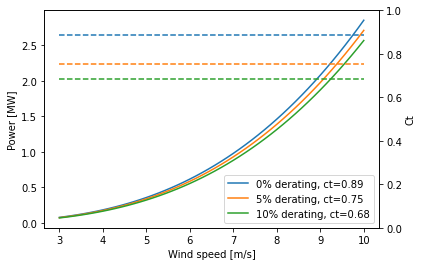

In [34]:
ax1 = plt.gca()
ax2 = plt.twinx(ax1)
ws = np.linspace(3, 10)
for derating in [0, .05, .1]:
    ct = wt.ct(ws, derating=derating)
    ax1.plot(ws, wt.power(ws, derating=derating) / 1e6, label='%d%% derating, ct=%.2f' % (derating * 100, ct[0]))
    ax2.plot(ws, ct,'--')

ax1.legend(loc='lower right')
ax1.set_xlabel('Wind speed [m/s]')
ax1.set_ylabel('Power [MW]')
ax2.set_ylabel('Ct')
ax2.set_ylim([0, 1])

#### Example, maximize mean power by optizing de-rating and hub height

In this example we will maximize the mean power by optimizing the individual wind turbine hub height and derating factors.

First we setup the `WindFarmModel` and the function to maximize, `mean_power`, which takes the hub height and derating factors as input:

In [35]:
from py_wake.deficit_models.gaussian import IEA37SimpleBastankhahGaussian
from py_wake.site import UniformSite
from py_wake.utils.gradients import autograd
from topfarm._topfarm import TopFarmProblem
from topfarm.cost_models.cost_model_wrappers import CostModelComponent
from topfarm.easy_drivers import EasyScipyOptimizeDriver

n_wt = 5
wfm = IEA37SimpleBastankhahGaussian(site=UniformSite(p_wd=[1],ti=.1), windTurbines=wt)
wt_x = np.arange(n_wt) * 4 * wt.diameter()
wt_y = np.zeros_like(wt_x)

def mean_power(zhub, derating):
    # WS_eff_ilk, TI_eff_ilk, power_ilk, ct_ilk, localWind, wt_inputs = wfm.calc_wt_interaction(...)
    # index 2 = power_ilk
    power_ilk = wfm.calc_wt_interaction(x_i=wt_x, y_i=wt_y, h_i=zhub, wd=[270], ws=[10], derating=derating)[2] 
    return np.mean(power_ilk)

Note, the normal `WindFarmModel.__call__` method, which is invoked by `wfm(x,y,...)` calls `WindFarmModel.calc_wt_interaction` and packs the result into a xarray dataset. This step breaks the autograd data flow. We therefore need to call [`WindFarmModel.calc_wt_interaction`](https://topfarm.pages.windenergy.dtu.dk/PyWake/api/WindFarmModel.html#py_wake.wind_farm_models.wind_farm_model.WindFarmModel.calc_wt_interaction) directly.

We use `autograd` to setup the gradient function. The input argument `argnum=[0,1]` makes it return the gradients of the `mean_power` function wrt. to both inputs, `zhub` and `derating`

In [36]:
dmean_power_dzhub_derating = autograd(mean_power, argnum=[0, 1])

In [37]:
dmean_power_dzhub_derating([100]*n_wt, [0]*n_wt)

[array([0., 0., 0., 0., 0.]),
 array([ 3.71659114e+20,  2.88392374e+20,  2.41722932e+20,  1.77225891e+20,
        -1.60329988e+05])]

Next step is to setup the `CostModelComponent`

In [38]:
cost_comp=CostModelComponent(input_keys=['zhub', 'derating'],
                              n_wt=n_wt,
                              cost_function=mean_power,
                              cost_gradient_function=dmean_power_dzhub_derating,
                              maximize=True # because we want to maximize the mean power
                             )

and the `TopFarmProblem`

In [39]:
tf = TopFarmProblem(design_vars={
                        # (initial_values, lower limit, upper limit)
                        'zhub': ([100]*n_wt, 80, 130),
                        'derating': ([0] * n_wt, 0, .9)},  
                    cost_comp=cost_comp,
                    expected_cost=1000, # expected cost impacts the size of the moves performed by the optimizer
                    )

INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings


As seen above the gradient of the mean power wrt. hub height is zero when all wind turbines have the same height. This means that the optimizer "thinks" that the solution cannot be improved. We therefore need to initialize the optimization with slightly different hub heights.

Furthermore, the derating must be above zero to avoid inequality constraint failure.

In [40]:
cost, state, recorder = tf.optimize(state={'zhub':np.arange(n_wt)+100, # 100,101,102,...
                                           'derating':[0.1]*n_wt # 10% initial derating
                                          })
print ()
print ('Optimized mean power', cost)
print ('Optimized state', state)

INFO: checking out_of_order
INFO: checking system
INFO: checking solvers
INFO: checking dup_inputs
INFO: checking missing_recorders
INFO: checking unserializable_options
INFO: checking comp_has_no_outputs
INFO: checking auto_ivc_warnings
Optimization terminated successfully    (Exit mode 0)
            Current function value: -1716.1873043790367
            Iterations: 38
            Function evaluations: 56
            Gradient evaluations: 36
Optimization Complete
-----------------------------------

Optimized mean power -1716187.3043790367
Optimized state {'zhub': array([ 80., 130.,  80.,  80., 130.]), 'derating': array([0.08691683, 0.06260834, 0.19990203, 0.04530914, 0.        ])}


plot result

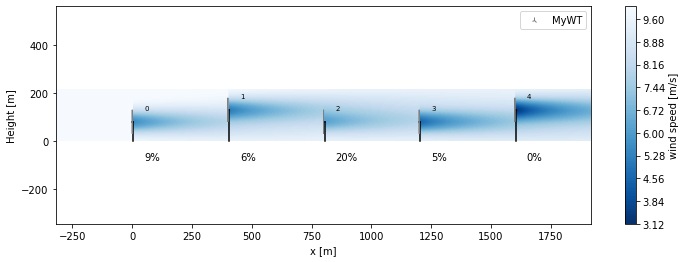

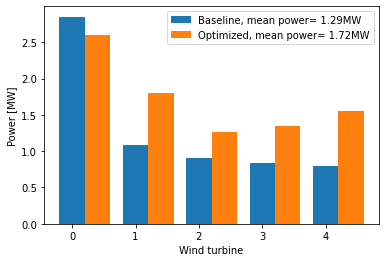

In [41]:
from py_wake import XZGrid
derating = state['derating']
h = state['zhub']

sim_res_ref = wfm(wt_x, wt_y, wd=[270], ws=[10], derating=[0] * n_wt)
sim_res_opt = wfm(wt_x, wt_y, h=h, wd=[270], ws=[10], derating=derating)
plt.figure(figsize=(12,4))
sim_res_opt.flow_map(XZGrid(y=0)).plot_wake_map()
for x_, d in zip(wt_x, derating):
    plt.text(x_ + 50, -80, "%d%%" % np.round(d * 100), fontsize=10)
plt.ylabel('Height [m]')
plt.xlabel('x [m]')

plt.figure()
for i, (sim_res, l) in enumerate([(sim_res_ref, 'Baseline'), (sim_res_opt, 'Optimized')]):
    plt.bar(np.arange(n_wt) + i * .4, sim_res.Power.squeeze() * 1e-6, width=.4,
            label='%s, mean power= %.2fMW' % (l, sim_res.Power.mean() * 1e-6))
plt.ylabel('Power [MW]')
plt.xlabel('Wind turbine')
plt.legend()
plt.show()

In [42]:
def test_manual_vs_autograd_speed():
    cubePowerSimpleCt = CubePowerSimpleCt()
    x = np.random.random(10000) * 30

    def t(method):
        autograd(method)(x, 0)
        autograd(method)(x, 1)
    t_autograd = np.mean(timeit(t, min_time=0.2)(cubePowerSimpleCt._power_ct)[1])
    t_manual = np.mean(timeit(t, min_time=.2)(cubePowerSimpleCt._power_ct_withgrad)[1])
    assert np.abs(t_manual - t_autograd) / t_manual < 0.08, (t_manual, t_autograd)